# ***State Clustering***

## **Data and Libraries Import**

`Libraries import`

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
from pathlib import Path
from dotenv import load_dotenv,find_dotenv

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from sqlalchemy import create_engine, text


import warnings
warnings.filterwarnings('ignore')

`Initializing the env-variables so that no one sees the actual credentials`

In [2]:
env_path = Path.cwd()/"github_repo_cloned"/"distribution_hub_optimizer"/".env"
load_dotenv(env_path)

HOST = os.getenv("DB_HOST")
USER = os.getenv("DB_USER")
PASSWORD = os.getenv("DB_PASSWORD")
PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")
OUTPUT_DIR = Path(os.getenv("OUTPUT_DIR", Path.cwd()/"outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

`Creating the engine to connect with the database`

In [3]:
engine = create_engine(f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DB_NAME}")


def sql(query, engine = engine):
    with engine.connect() as conn:
        df = pd.read_sql(text(query),conn)
    return df

In [4]:
# CSVs saved by notebooks 01 and 02
growth = pd.read_csv(OUTPUT_DIR/"growth_summary.csv")
gsdp_gain = pd.read_csv(OUTPUT_DIR/"state_classification.csv")
amount = pd.read_csv(OUTPUT_DIR/"amount_data.csv", parse_dates=['ds'])

# Per capita level is not in the CSVs, so it comes from the view
query = 'select state, avg_per_capita_amount from cluster_data'
per_capita = sql(query=query, engine=engine)

In [5]:
growth.head()

,unique_id,volume_growth,amount_growth,volume_growth_y2,amount_growth_y2
0,andaman and nicobar,11.63,31.85,8.24,13.62
1,andhra pradesh,16.01,16.52,9.29,11.39
2,arunachal pradesh,13.94,32.45,6.82,22.68
3,assam,18.39,9.13,9.10,7.85
4,bihar,17.97,13.20,9.68,10.52


In [6]:
gsdp_gain.head()

,state,from_fy,to_fy,per_capita_gain_pct,gsdp_gain_pct,gain_gap_pct,quick_class,state_class
0,arunachal pradesh,2019-20,2023-24,121.43,46.52,74.91,goods outgrowing economy,Strong Outperformer
1,tripura,2019-20,2023-24,102.78,52.58,50.20,goods outgrowing economy,Strong Outperformer
2,chhattisgarh,2019-20,2023-24,95.24,46.77,48.47,goods outgrowing economy,Strong Outperformer
3,meghalaya,2019-20,2023-24,84.00,36.27,47.73,goods outgrowing economy,Strong Outperformer
4,odisha,2019-20,2023-24,99.15,54.94,44.21,goods outgrowing economy,Strong Outperformer


In [7]:
amount.head()

,unique_id,ds,y
0,andaman and nicobar,2019-04-01,229.59
1,andaman and nicobar,2019-05-01,276.99
2,andaman and nicobar,2019-06-01,190.68
3,andaman and nicobar,2019-07-01,217.12
4,andaman and nicobar,2019-08-01,228.28


In [8]:
per_capita.head()

,state,avg_per_capita_amount
0,jammu and kashmir,0.0106
1,himachal pradesh,0.0443
2,punjab,0.0389
3,haryana,0.0793
4,delhi,0.0724


## **Initial Data Check**

In [9]:
for name, df in [('growth', growth), ('gsdp_gain', gsdp_gain), ('amount', amount), ('per_capita', per_capita)]:
    print(f"{name}: {df.shape[0]} rows | {df.isnull().sum().sum()} nulls")

growth: 35 rows | 0 nulls
gsdp_gain: 33 rows | 0 nulls
amount: 2940 rows | 0 nulls
per_capita: 33 rows | 0 nulls


In [10]:
# Same state key in every source
growth = growth.rename(columns={'unique_id':'state'})
amount = amount.rename(columns={'unique_id':'state', 'y':'amount'})

print("Duplicate states:")
print(f"growth: {growth['state'].duplicated().sum()} | gsdp_gain: {gsdp_gain['state'].duplicated().sum()} | per_capita: {per_capita['state'].duplicated().sum()}")

Duplicate states:
growth: 0 | gsdp_gain: 0 | per_capita: 0


In [11]:
state_sets = {
    'growth': set(growth['state']),
    'gsdp_gain': set(gsdp_gain['state']),
    'amount': set(amount['state']),
    'per_capita': set(per_capita['state'])
}
common = set.intersection(*state_sets.values())
print(f"States in all sources: {len(common)}")
for name, s in state_sets.items():
    print(f"Dropped from {name}:", sorted(s - common))

States in all sources: 33
Dropped from growth: ['dadra and nagar haveli and daman and diu', 'lakshadweep']
Dropped from gsdp_gain: []
Dropped from amount: ['dadra and nagar haveli and daman and diu', 'lakshadweep']
Dropped from per_capita: []


## **Feature Preparation**

`Volatility`

In [12]:
amount = amount.sort_values(['state','ds'])
amount['amount'] = amount['amount'].where(amount['amount'] > 0)
amount['log_change'] = amount.groupby('state')['amount'].transform(lambda s: np.log(s).diff())

volatility = amount.groupby('state')['log_change'].std().mul(100).round(2).reset_index(name='volatility_pct')
volatility.sort_values('volatility_pct', ascending=False).head()

,state,volatility_pct
17,lakshadweep,60.41
7,dadra and nagar haveli and daman and diu,50.16
25,puducherry,42.89
10,gujarat,36.79
16,kerala,33.80


`Feature Table`

In [13]:
features = (
    growth[['state','amount_growth']].rename(columns={'amount_growth':'forecast_growth_pct'})
    .merge(gsdp_gain[['state','gsdp_gain_pct']], on='state')
    .merge(per_capita, on='state')
    .merge(volatility, on='state')
)
features = features.dropna().reset_index(drop=True)

print(f"States clustered: {features.shape[0]}")
features.head()

States clustered: 33


,state,forecast_growth_pct,gsdp_gain_pct,avg_per_capita_amount,volatility_pct
0,andaman and nicobar,31.85,28.00,0.0022,18.84
1,andhra pradesh,16.52,55.50,0.0220,7.90
2,arunachal pradesh,32.45,46.52,0.0066,15.16
3,assam,9.13,63.01,0.0089,9.06
4,bihar,13.20,46.85,0.0029,8.27


In [14]:
# Per capita amount is a level that is heavily skewed (small states and UTs), so use its log
features['per_capita_log'] = np.log(features['avg_per_capita_amount'])

FEATURES = ['forecast_growth_pct','per_capita_log','gsdp_gain_pct','volatility_pct']
FEATURE_LABELS = {
    'forecast_growth_pct':'Forecast Growth',
    'per_capita_log':'Per Capita',
    'gsdp_gain_pct':'GSDP Growth',
    'volatility_pct':'Volatility'
}

features[FEATURES].describe().round(2)

,forecast_growth_pct,per_capita_log,gsdp_gain_pct,volatility_pct
count,33.00,33.00,33.00,33.00
mean,14.39,-3.98,45.79,15.29
std,6.37,1.12,8.78,9.63
min,2.03,-6.12,26.88,7.10
25%,10.60,-4.72,40.98,8.94
50%,13.20,-4.05,46.85,11.36
75%,16.52,-3.12,52.40,17.02
max,32.45,-1.46,63.01,42.89


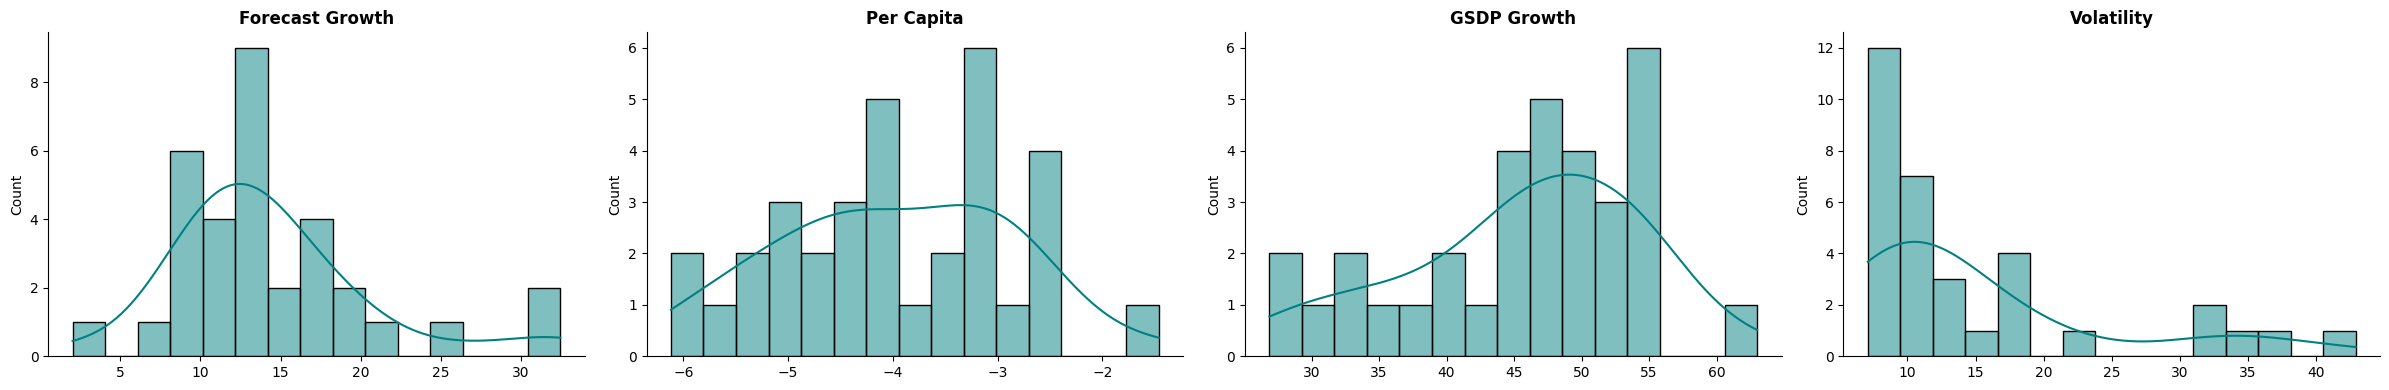

In [15]:
fig, ax = plt.subplots(1, 4, figsize=(24,4))
for a, col in zip(ax, FEATURES):
    sns.histplot(features[col], bins=15, kde=True, color='teal', ax=a)
    a.set_title(FEATURE_LABELS[col], weight='bold')
    a.set_xlabel('')
sns.despine()
plt.tight_layout()
plt.show()

In [16]:
# Strong outliers (|z| > 3) will pull a cluster of their own, worth knowing about
z_check = (features[FEATURES] - features[FEATURES].mean()) / features[FEATURES].std()
outliers = features.loc[(z_check.abs() > 3).any(axis=1), ['state'] + FEATURES]
outliers

,state,forecast_growth_pct,per_capita_log,gsdp_gain_pct,volatility_pct


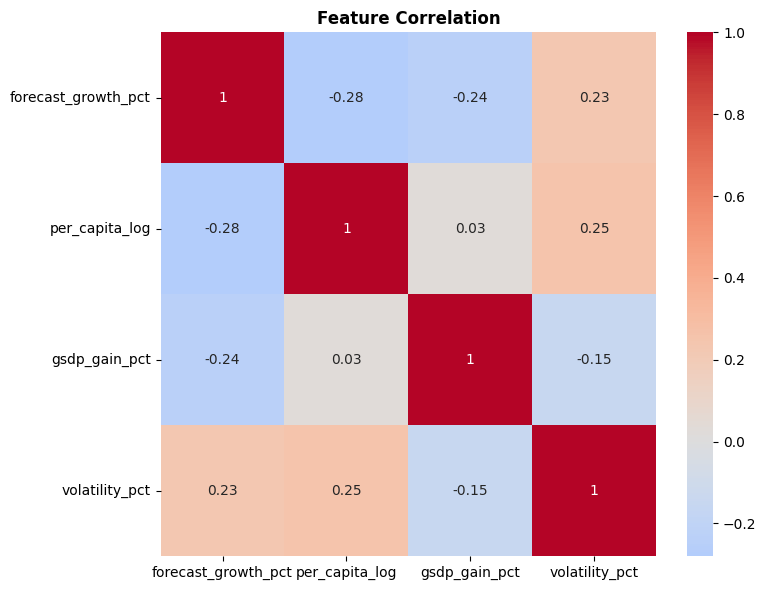

In [17]:
plt.figure(figsize=(8,6))
sns.heatmap(features[FEATURES].corr().round(2), annot=True, cmap='coolwarm', center=0)
plt.title('Feature Correlation', weight='bold')
plt.tight_layout()
plt.show()

`Scaling`

In [18]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(features[FEATURES]), columns=FEATURES, index=features['state'])

X_scaled.describe().round(2).loc[['mean','std']]

,forecast_growth_pct,per_capita_log,gsdp_gain_pct,volatility_pct
mean,-0.00,0.00,-0.00,0.00
std,1.02,1.02,1.02,1.02


`Choosing k using elbow method`

In [19]:
K_RANGE = range(2, 9)
K_MIN = 3          # 2 clusters is too coarse to pick hubs from
K_OVERRIDE = None  # set a number to force k after looking at the plots

k_results = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_scaled)
    k_results.append({
        'k': k,
        'inertia': km.inertia_,
        'silhouette': silhouette_score(X_scaled, labels),
        'smallest_cluster': pd.Series(labels).value_counts().min()
    })

k_selection = pd.DataFrame(k_results).round(3)
k_selection

,k,inertia,silhouette,smallest_cluster
0,2,97.232,0.299,11
1,3,70.454,0.357,5
2,4,55.656,0.267,4
3,5,46.214,0.282,3
4,6,37.302,0.292,1
5,7,30.450,0.299,1
6,8,25.441,0.308,1


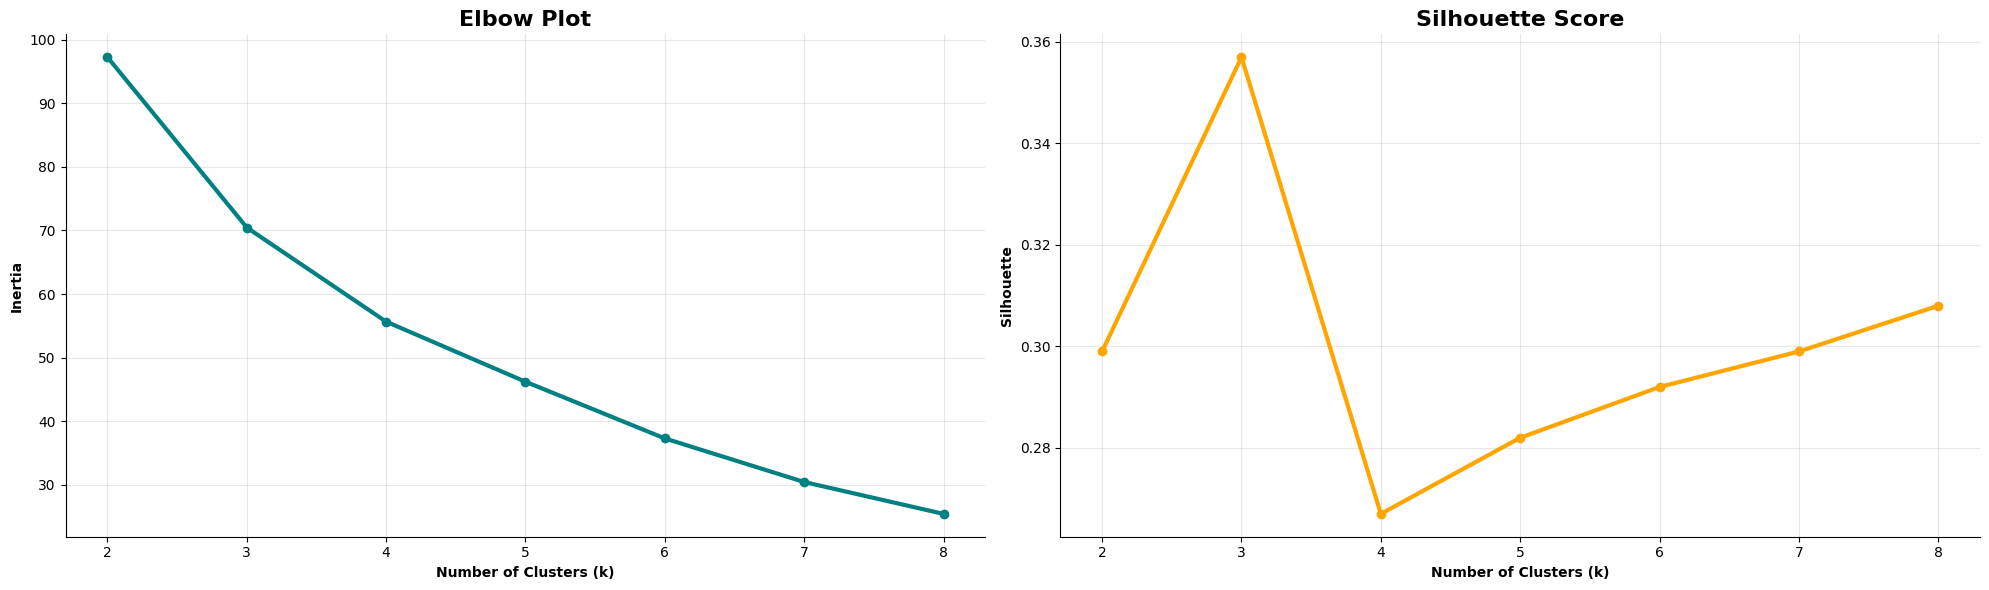

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(20,6))

ax[0].plot(k_selection['k'], k_selection['inertia'], marker='o', color='teal', linewidth=3)
ax[0].set_title('Elbow Plot', fontsize=16, weight='bold')
ax[0].set_xlabel('Number of Clusters (k)', weight='bold')
ax[0].set_ylabel('Inertia', weight='bold')

ax[1].plot(k_selection['k'], k_selection['silhouette'], marker='o', color='orange', linewidth=3)
ax[1].set_title('Silhouette Score', fontsize=16, weight='bold')
ax[1].set_xlabel('Number of Clusters (k)', weight='bold')
ax[1].set_ylabel('Silhouette', weight='bold')

for a in ax:
    a.set_xticks(list(K_RANGE))
    a.grid(alpha=0.3)
sns.despine()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"cluster_k_selection.png", dpi=150, bbox_inches='tight')
plt.show()

In [21]:
# Highest silhouette among k >= K_MIN, unless overridden
eligible = k_selection[k_selection['k'] >= K_MIN]
K = int(K_OVERRIDE or eligible.loc[eligible['silhouette'].idxmax(), 'k'])
print(f"Chosen k: {K}")

Chosen k: 3


## **Clustering**

In [22]:
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42)
features['cluster_id'] = kmeans.fit_predict(X_scaled)

features['cluster_id'].value_counts().sort_index().reset_index(name='states')

,cluster_id,states
0,0,5
1,1,23
2,2,5


`Naming The Clusters`

In [23]:
centroids = X_scaled.groupby(features['cluster_id'].values).mean()
centroids.round(2)

,forecast_growth_pct,per_capita_log,gsdp_gain_pct,volatility_pct
0,1.81,-1.12,-0.48,0.20
1,-0.41,0.05,0.12,-0.51
2,0.08,0.88,-0.09,2.16


In [24]:
def name_cluster(z_row, threshold=0.5, max_parts=2):
    strong = z_row[z_row.abs() >= threshold].sort_values(key=lambda s: s.abs(), ascending=False).head(max_parts)
    if strong.empty:
        return 'Average Profile'
    return ', '.join(f"{'High' if v > 0 else 'Low'} {FEATURE_LABELS[f]}" for f, v in strong.items())


names = {cid: name_cluster(centroids.loc[cid]) for cid in centroids.index}

# Make sure two clusters never share a name
dup = pd.Series(names).duplicated(keep=False)
names = {cid: (f"{n} (C{cid})" if dup[cid] else n) for cid, n in names.items()}

HUB_WEIGHTS = {'forecast_growth_pct':1, 'per_capita_log':1, 'gsdp_gain_pct':1, 'volatility_pct':-1}
hub_score = sum(centroids[f] * w for f, w in HUB_WEIGHTS.items()) / sum(abs(w) for w in HUB_WEIGHTS.values())
hub_rank = hub_score.rank(ascending=False, method='first').astype(int)

features['cluster_name'] = features['cluster_id'].map(names)
features['cluster_hub_score'] = features['cluster_id'].map(hub_score.round(2))
features['cluster_rank'] = features['cluster_id'].map(hub_rank)

In [25]:
cluster_summary = features.groupby(['cluster_id','cluster_name','cluster_rank','cluster_hub_score']).agg(
    states=('state','count'),
    avg_forecast_growth_pct=('forecast_growth_pct','mean'),
    avg_per_capita_amount=('avg_per_capita_amount','mean'),
    avg_gsdp_gain_pct=('gsdp_gain_pct','mean'),
    avg_volatility_pct=('volatility_pct','mean'),
    state_list=('state', lambda s: ', '.join(s.str.title()))
).round(2).reset_index().sort_values('cluster_rank')

cluster_summary

,cluster_id,cluster_name,cluster_rank,cluster_hub_score,states,avg_forecast_growth_pct,avg_per_capita_amount,avg_gsdp_gain_pct,avg_volatility_pct,state_list
1,1,Low Volatility,1,0.07,23,11.82,0.03,46.87,10.43,"Andhra Pradesh, Assam, Bihar, Chandigarh, Chha..."
0,0,"High Forecast Growth, Low Per Capita",2,0.00,5,25.71,0.01,41.66,17.18,"Andaman And Nicobar, Arunachal Pradesh, Manipu..."
2,2,"High Volatility, High Per Capita",3,-0.32,5,14.90,0.08,44.99,35.75,"Gujarat, Kerala, Maharashtra, Puducherry, Tami..."


In [26]:
print("States in the top ranked cluster:")
features[features['cluster_rank'] == 1][['state','forecast_growth_pct','avg_per_capita_amount','gsdp_gain_pct','volatility_pct']].round(2)

States in the top ranked cluster:


,state,forecast_growth_pct,avg_per_capita_amount,gsdp_gain_pct,volatility_pct
1,andhra pradesh,16.52,0.02,55.50,7.90
3,assam,9.13,0.01,63.01,9.06
4,bihar,13.20,0.00,46.85,8.27
5,chandigarh,10.60,0.05,44.02,9.62
6,chhattisgarh,18.89,0.02,46.77,8.10
7,delhi,17.01,0.07,39.71,11.36
8,goa,11.55,0.08,41.98,11.81
10,haryana,14.82,0.08,48.44,9.22
11,himachal pradesh,9.76,0.04,30.32,7.10
12,jammu and kashmir,9.24,0.01,50.19,10.82


## **Visualization**

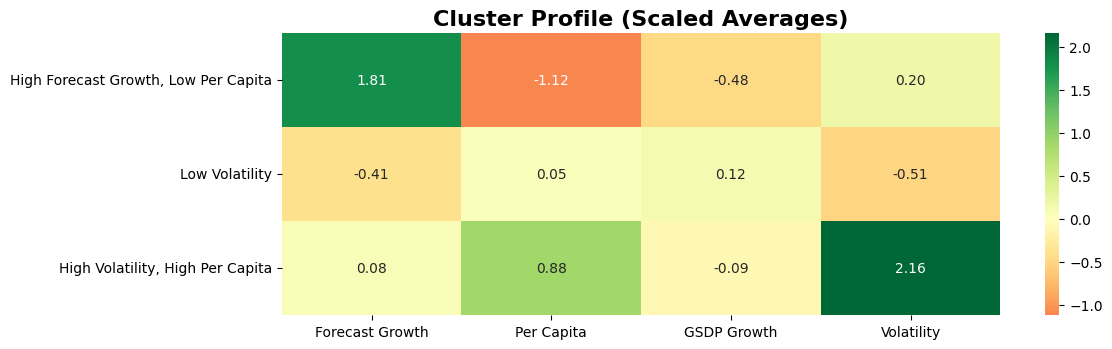

In [27]:
plt.figure(figsize=(12, max(3, K * 1.2)))
heat = centroids.rename(index=names, columns=FEATURE_LABELS)
sns.heatmap(heat, annot=True, fmt='.2f', cmap='RdYlGn', center=0)
plt.title('Cluster Profile (Scaled Averages)', fontsize=16, weight='bold')
plt.ylabel('')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"cluster_profile_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

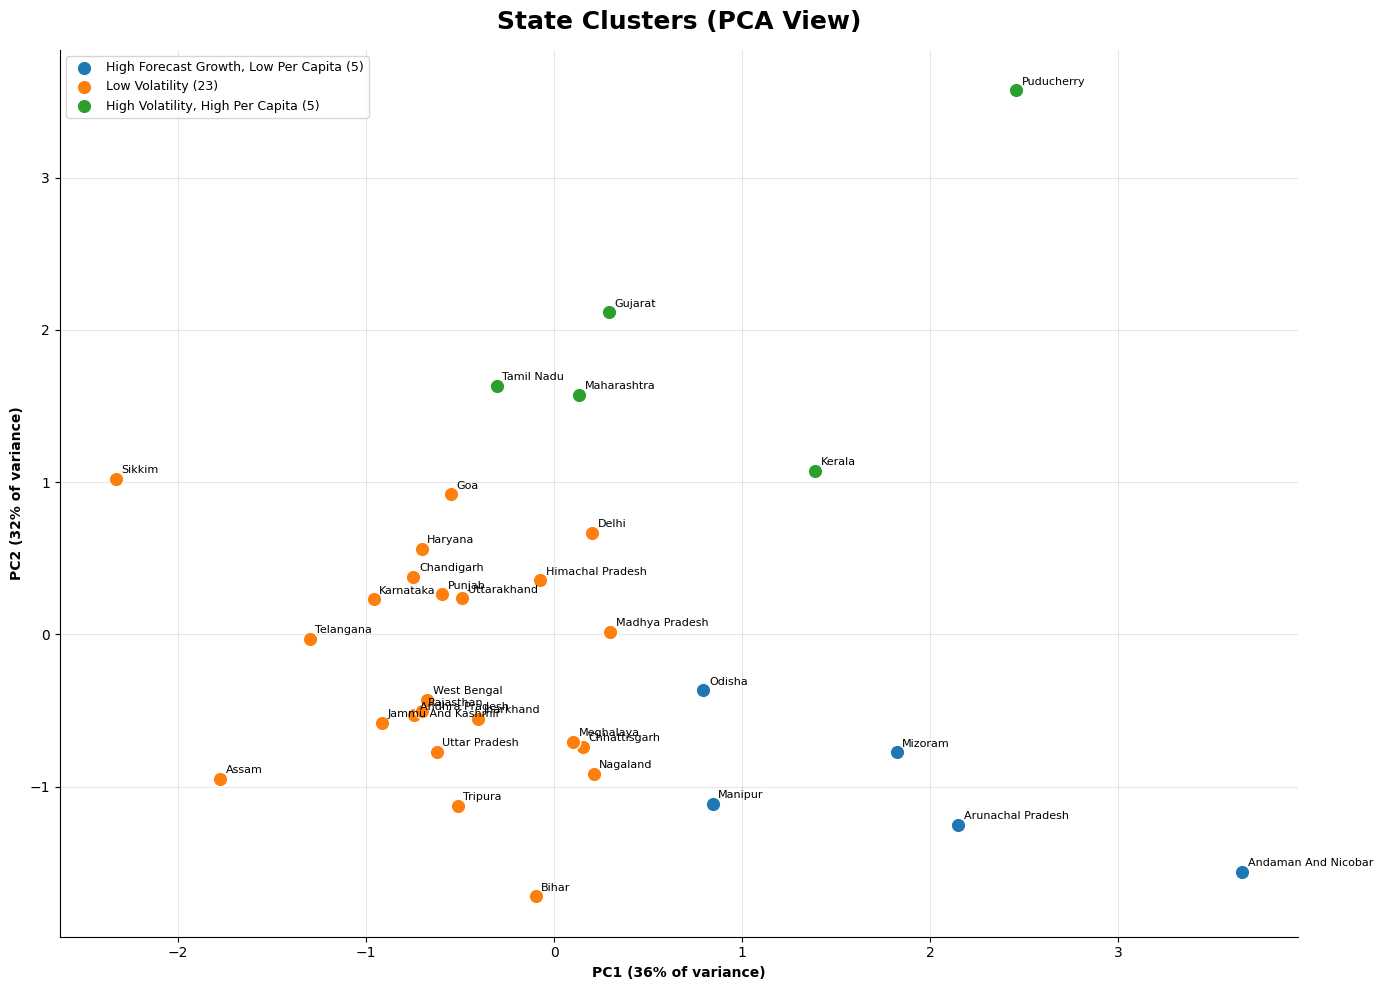

In [28]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
features['pc1'] = coords[:, 0]
features['pc2'] = coords[:, 1]

fig, ax = plt.subplots(figsize=(14,10))
palette = sns.color_palette('tab10', n_colors=K)
for cid, color in zip(sorted(names), palette):
    sub = features[features['cluster_id'] == cid]
    ax.scatter(sub['pc1'], sub['pc2'], s=110, color=color, edgecolor='white',
               label=f"{names[cid]} ({len(sub)})", zorder=3)

for _, r in features.iterrows():
    ax.annotate(r['state'].title(), (r['pc1'], r['pc2']), xytext=(4,4), textcoords='offset points', fontsize=8)

ax.set_title('State Clusters (PCA View)', fontweight='bold', fontsize=18, pad=15)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% of variance)", weight='bold')
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% of variance)", weight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(alpha=0.3)
sns.despine()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"state_clusters_pca.png", dpi=150, bbox_inches='tight')
plt.show()

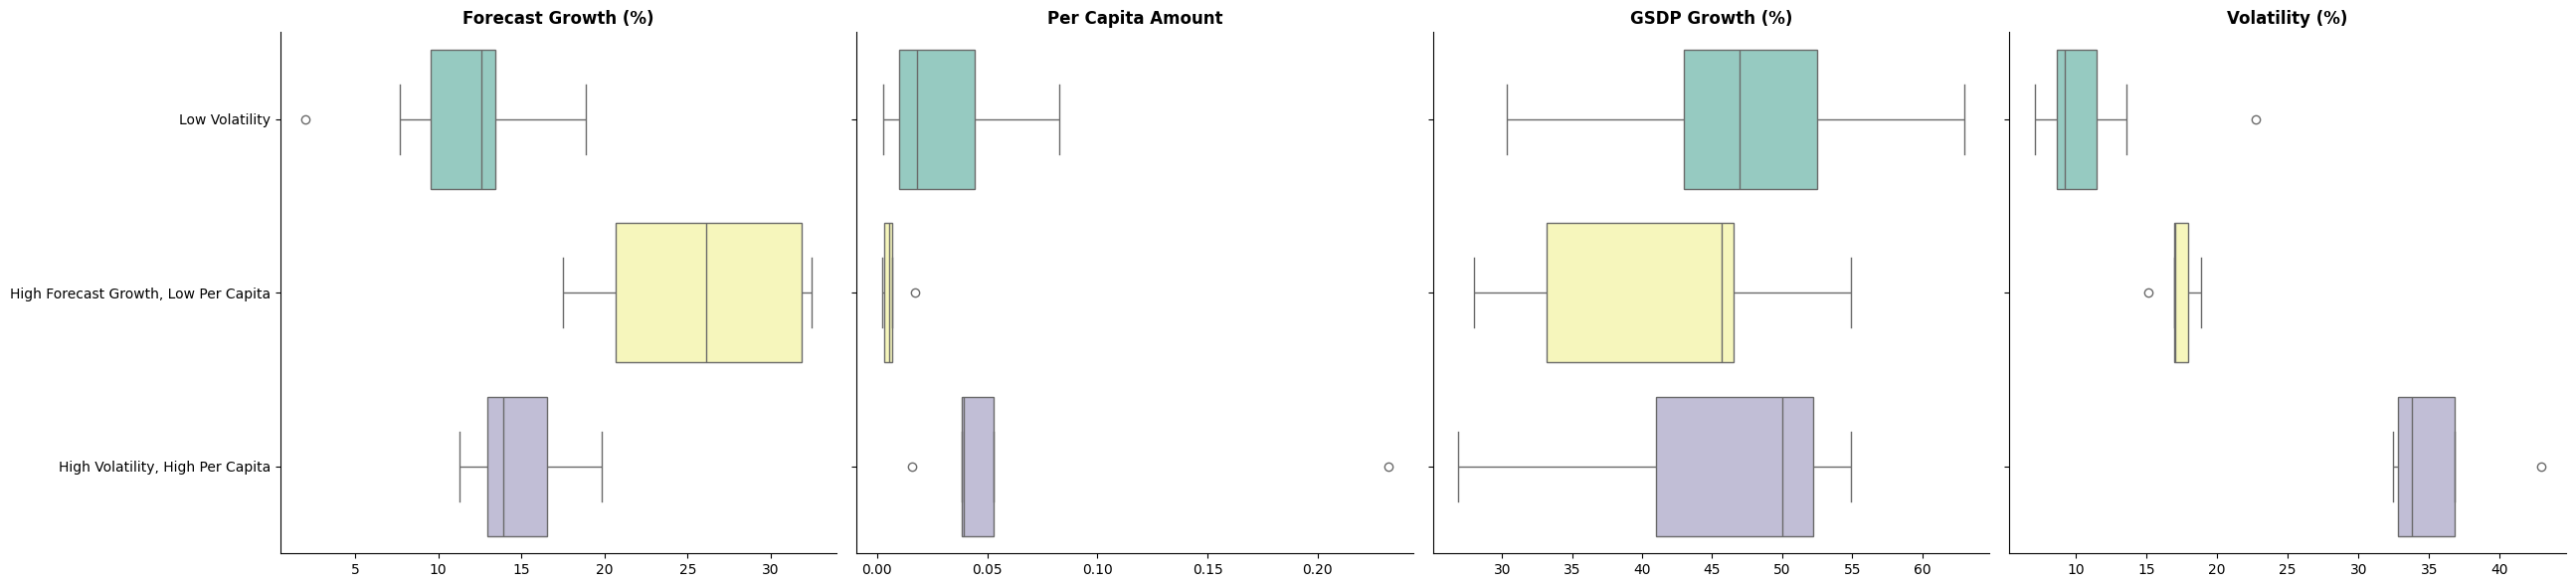

In [29]:
plot_cols = {
    'forecast_growth_pct':'Forecast Growth (%)',
    'avg_per_capita_amount':'Per Capita Amount',
    'gsdp_gain_pct':'GSDP Growth (%)',
    'volatility_pct':'Volatility (%)'
}
order = cluster_summary['cluster_name'].tolist()

fig, ax = plt.subplots(1, 4, figsize=(26,6))
for a, (col, label) in zip(ax, plot_cols.items()):
    sns.boxplot(x=col, y='cluster_name', data=features, order=order, palette='Set3', ax=a)
    a.set_title(label, weight='bold')
    a.set_xlabel('')
    a.set_ylabel('')
for a in ax[1:]:
    a.set_yticklabels([])
sns.despine()
plt.tight_layout()
plt.show()

`Save Outputs`

In [30]:
state_clusters = features[['state','forecast_growth_pct','avg_per_capita_amount','gsdp_gain_pct','volatility_pct',
                           'cluster_id','cluster_name','cluster_hub_score','cluster_rank']].sort_values(['cluster_rank','state'])
state_clusters.to_csv(OUTPUT_DIR/"state_clusters.csv", index=False)

In [31]:
cluster_summary.to_csv(OUTPUT_DIR/"cluster_summary.csv", index=False)
k_selection.to_csv(OUTPUT_DIR/"cluster_k_selection.csv", index=False)